# Predicting Meropenem Resistance in Klebsiella pneumoniae Using Antimicrobial Resistance Genes

Computing Bioinformatics group project. Executed research analysis, not a clinical diagnostic.
Snapshot: 18 November 2026. The group confirmed lecturer approval of the question and all four objectives.
The approved primary predictors are KPC family, NDM family and exact blaOXA-48.

## 1. Question and objectives
Question: Can the presence or absence of known antimicrobial-resistance genes in K. pneumoniae
predict whether an isolate is resistant or susceptible to meropenem?

1. Acquire and document public resistance-gene profiles and matched laboratory meropenem results.
2. Clean and explore the dataset, including ambiguous results and gene frequencies.
3. Assess associations between individual resistance genes and meropenem resistance.
4. Develop and evaluate classifiers against a simple baseline.

Hypothesis: these three gene features contain predictive information beyond a majority-class baseline.
Statistical null hypotheses test no association between each feature and resistance. Association is not causation.
KPC/NDM refer to families, OXA-48 to the exact allele; OXA-181/OXA-232 are not silently added.

In [1]:
import importlib.util, subprocess, sys
needed = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
          'sklearn':'scikit-learn', 'matplotlib':'matplotlib'}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import json, hashlib, base64, zlib, re, platform
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from scipy.stats.contingency import odds_ratio
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay)
from IPython.display import display, Markdown
SEED = 146412
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':10})
versions = {m.__name__: m.__version__ for m in [np,pd,scipy,sklearn,matplotlib]}
versions['python'] = platform.python_version()
(RESULTS/'environment.json').write_text(json.dumps(versions,indent=2))
print(versions)
def show_table(frame, name):
    frame.to_csv(RESULTS/(name+'.csv'),index=False)
    display(frame)
def save_plot(name):
    plt.tight_layout(); plt.savefig(RESULTS/(name+'.png'),bbox_inches='tight'); plt.show()
def say(text):
    display(Markdown(text))

{'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'matplotlib': '3.10.0', 'python': '3.13.18'}


## 2. Data acquisition
Source: [NCBI AST Browser](https://www.ncbi.nlm.nih.gov/pathogens/docs/ast/) and
[Isolates Browser](https://www.ncbi.nlm.nih.gov/pathogens/isolates/).
The discovery query was `antibiotic:meropenem AND scientific_name:"Klebsiella pneumoniae"`.
The AST endpoint returned 1,172 test records; 1,169 unique BioSamples were queried in batches of 100
against the isolates collection. Both returned counts and identity matches were checked.

The target is a submitted laboratory phenotype, not a phenotype inferred from the selected genes.
NCBI AMRFinderPlus calls are the genomic input. Existing annotations are used instead of rerunning raw-read
assembly or AMRFinderPlus in Colab; this is a genomic annotation study. Accessions permit further sequence audit.
NCBI reports that it does not independently vet all submitted AST field relationships.

Files: `ncbi_ast_full.json` is the complete AST response; `ncbi_matched_isolates.json` is the list of
matched genome metadata and AMRFinderPlus calls. The code below restores their exact bytes and checks SHA-256.
`src/refresh_ncbi.py` can acquire a new snapshot separately; replacing this snapshot changes the study.

NCBI places no restrictions of its own on molecular-data use, while noting possible submitter rights.
See [data policy](https://www.ncbi.nlm.nih.gov/home/about/policies/). Cite NCBI and original studies.
No age, sex or patient identifier is used as a feature. Do not add patient metadata to public results.

In [2]:
SNAPSHOTS = {'ncbi_ast_full.json': {'sha256': 'a244a0c108812524f6092a099b5356d8a368aa876bf1a83003b398c5148cad52', 'zlib_base64': '...'}, 'ncbi_matched_isolates.json': {'sha256': 'aebb3f98485bfc04a80f09d76fd6bcf315505a5ce057599d9549786023ca7a08', 'zlib_base64': '...'}}
raw = {}
for filename, package in SNAPSHOTS.items():
    content = zlib.decompress(base64.b64decode(package['zlib_base64']))
    assert hashlib.sha256(content).hexdigest() == package['sha256'], filename
    raw[filename] = json.loads(content)
ast = raw['ncbi_ast_full.json']['ngout']['data']['content']
genomes = raw['ncbi_matched_isolates.json']
assert len(ast) == raw['ncbi_ast_full.json']['ngout']['data']['totalCount']
assert len(genomes) == len({g['biosample_acc'] for g in genomes})
assert {a['biosample_acc'] for a in ast} == {g['biosample_acc'] for g in genomes}
assert all(a['antibiotic']=='meropenem' for a in ast)
print(f'{len(ast)} laboratory test rows; {len(genomes)} distinct matched isolates.')

1172 laboratory test rows; 1169 distinct matched isolates.


In [3]:
dictionary = pd.DataFrame([
 ('biosample','NCBI BioSample accession; exact join key'),
 ('assembly','NCBI genome assembly accession; genomic traceability'),
 ('target','Pathogen Detection target accession; secondary linkage check'),
 ('project','BioProject accession; provenance and study-held-out evaluation'),
 ('cluster','NCBI PDS cluster without version, or unique BioSample if unavailable'),
 ('cluster_known','Whether a PDS cluster was provided'),
 ('country','First geographic component; description only'),
 ('standard','CLSI/EUCAST or missing, as submitted; edition unknown'),
 ('phenotype','Submitted meropenem laboratory category'),
 ('y','Target: resistant=1, susceptible=0'),
 ('blaKPC','1=complete KPC-family call; 0=no target hit after successful analysis'),
 ('blaNDM','1=complete NDM-family call; 0=no target hit after successful analysis'),
 ('blaOXA48','1=complete exact blaOXA-48 call; 0=no exact/ambiguous target hit'),
 ('length_bp','Provider assembly length, base pairs'),
 ('contigs','Provider assembly contig count'),
 ('n50','Provider contig N50, base pairs'),
 ('amr_version','AMRFinderPlus software version'),
 ('db_version','Reference gene database version'),
 ('analysis_type','COMBINED or NUCLEOTIDE annotation mode'),
 ('calls','Unaltered list of AMRFinderPlus gene symbols and statuses'),
 ('ast_count','Number of submitted meropenem measurements for that isolate'),
 ('exclusion','First applicable exclusion reason in the prespecified QC order'),
],columns=['variable','definition'])
show_table(dictionary,'data_dictionary')
# Inventory every original field, including fields not used in analysis.
inventory=[]
for source, records in [('AST',ast),('isolate',genomes)]:
    for field in sorted(set().union(*(r.keys() for r in records))):
        values=[r[field] for r in records if field in r]
        inventory.append({'source':source,'field':field,'present_records':len(values),
                          'types':','.join(sorted({type(v).__name__ for v in values}))})
show_table(pd.DataFrame(inventory),'source_field_inventory')

,variable,definition
0,biosample,NCBI BioSample accession; exact join key
1,assembly,NCBI genome assembly accession; genomic tracea...
2,target,Pathogen Detection target accession; secondary...
3,project,BioProject accession; provenance and study-hel...
4,cluster,"NCBI PDS cluster without version, or unique Bi..."
5,cluster_known,Whether a PDS cluster was provided
6,country,First geographic component; description only
7,standard,"CLSI/EUCAST or missing, as submitted; edition ..."
8,phenotype,Submitted meropenem laboratory category
9,y,"Target: resistant=1, susceptible=0"


,source,field,present_records,types
0,AST,_version_,1172,int
1,AST,antibiotic,1172,str
2,AST,bioproject_acc,1172,str
3,AST,biosample_acc,1172,str
4,AST,collection_date,1003,str
...,...,...,...,...
97,isolate,tree_node_ids,836,list
98,isolate,updatedate,1169,str
99,isolate,virulence_genotypes,617,list
100,isolate,wgs_acc_prefix,880,str


### Raw source field dictionary

All fields in the retrieved snapshots are listed. Only the documented analysis variables are used. Optional fields can be absent. For unused provider internal fields, no biological interpretation is asserted.

| Collection | Field | Description |
|---|---|---|
| AST | `_version_` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| AST | `antibiotic` | Drug tested; meropenem throughout this AST subset. |
| AST | `bioproject_acc` | Originating NCBI BioProject accession. |
| AST | `biosample_acc` | BioSample accession identifying the biological sample; primary join key. |
| AST | `collection_date` | Submitter-supplied collection date; may be partial or absent. |
| AST | `creation_date` | Record creation timestamp in the provider system. |
| AST | `disk_diffusion` | Laboratory inhibition-zone diameter in millimetres; not an MIC. |
| AST | `epi_type` | Provider clinical/environmental classification. |
| AST | `geo_loc_name` | Geographic origin string, possibly including subnational detail. |
| AST | `host` | Host organism, where supplied; not a predictor. |
| AST | `id` | Provider row identifier; AST and isolate collections have different row identities. |
| AST | `isolation_source` | Material or site from which the isolate was obtained. |
| AST | `measurement_sign` | Comparison operator attached to MIC or disk measurement; preserve inequalities. |
| AST | `mic` | Minimum inhibitory concentration in mg/L; read with measurement_sign. |
| AST | `phenotype` | Submitted laboratory susceptibility category, not a gene-derived prediction. |
| AST | `platform` | Laboratory susceptibility-test platform. |
| AST | `reagent` | Laboratory method version or reagent information. |
| AST | `scientific_name` | Submitted organism name. |
| AST | `standard` | Submitted testing standard (CLSI/EUCAST); does not specify a verified edition here. |
| AST | `target_acc` | Pathogen Detection target accession, including version. |
| AST | `target_creation_date` | Date the target entered the Pathogen Detection system. |
| AST | `taxgroup_name` | Pathogen Detection organism group name. |
| AST | `vendor` | Manufacturer of the susceptibility testing equipment/reagent. |
| isolate | `AMR_genotypes` | AMRFinderPlus resistance calls including gene symbols and call statuses. |
| isolate | `AMR_genotypes_core` | Subset of resistance calls in the core AMRFinderPlus scope. |
| isolate | `AST_phenotypes` | Other submitted antibiotic phenotypes; excluded from predictors to prevent leakage. |
| isolate | `IFSAC_category` | Food-source categorization supplied by the provider; unused. |
| isolate | `LibraryLayout` | Sequencing library layout, e.g. paired-end. |
| isolate | `Platform` | Sequencing platform; distinct from lowercase AST platform. |
| isolate | `Run` | Sequence Read Archive run accession(s). |
| isolate | `_version_` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `amrfinderplus_analysis_type` | Annotation mode, including nucleotide-only or combined evidence. |
| isolate | `amrfinderplus_applied` | Provider indicator that AMRFinderPlus was applied. |
| isolate | `amrfinderplus_version` | AMRFinderPlus software version. |
| isolate | `asm_acc` | Genome assembly accession. |
| isolate | `asm_display_name` | Provider assembly display label. |
| isolate | `asm_level` | Assembly-level designation, e.g. contig. |
| isolate | `asm_stats_contig_n50` | Provider contig N50 length in base pairs. |
| isolate | `asm_stats_length_bp` | Provider total assembly length in base pairs. |
| isolate | `asm_stats_n_contig` | Provider number of assembly contigs. |
| isolate | `assembly_method` | Assembler name/version as supplied. |
| isolate | `assembly_uid` | NCBI Assembly numeric record identifier. |
| isolate | `attribute_package` | BioSample submission package name. |
| isolate | `bioproject_acc` | Originating NCBI BioProject accession. |
| isolate | `bioproject_center` | Submitting BioProject organization. |
| isolate | `biosample_acc` | BioSample accession identifying the biological sample; primary join key. |
| isolate | `cluster_size` | Provider cluster membership count; not necessarily the size in this subset. |
| isolate | `clustered` | Provider clustering indicator. |
| isolate | `collected_by` | Submitter-supplied collecting organization. |
| isolate | `collection_date` | Submitter-supplied collection date; may be partial or absent. |
| isolate | `complete_fl` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `creation_date` | Record creation timestamp in the provider system. |
| isolate | `epi_type` | Provider clinical/environmental classification. |
| isolate | `erd_group` | Provider relatedness/cluster identifier; fallback group key. |
| isolate | `erd_group_acc` | Unversioned relatedness/cluster accession. |
| isolate | `food_origin` | Food-origin metadata, where supplied; unused. |
| isolate | `fullasm_id` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `geo_loc_name` | Geographic origin string, possibly including subnational detail. |
| isolate | `host` | Host organism, where supplied; not a predictor. |
| isolate | `host_disease` | Submitter host-disease metadata; unused. |
| isolate | `id` | Provider row identifier; AST and isolate collections have different row identities. |
| isolate | `isolate_identifiers` | List of isolate aliases; not assumed to be patient identifiers. |
| isolate | `isolate_name_alias` | Alternative isolate name. |
| isolate | `isolation_source` | Material or site from which the isolate was obtained. |
| isolate | `kmer_group` | Versioned organism analysis group; not used as an isolate relatedness cluster. |
| isolate | `kmer_group_acc` | Unversioned organism analysis group accession. |
| isolate | `lat_lon` | Submitted latitude/longitude; unused. |
| isolate | `major_contributor` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `mindiff` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `minsame` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `new` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `number_amr_genes` | Provider count of resistance gene calls; excluded from predictors. |
| isolate | `number_core_amr_genes` | Provider count of core-scope resistance calls. |
| isolate | `number_drugs_intermediate` | Count of intermediate drug phenotypes; excluded from predictors. |
| isolate | `number_drugs_resistant` | Count of resistant drug phenotypes; excluded from predictors. |
| isolate | `number_drugs_susceptible` | Count of susceptible drug phenotypes; excluded from predictors. |
| isolate | `number_drugs_tested` | Count of drugs tested; excluded from predictors. |
| isolate | `number_stress_genes` | Provider count of stress-response calls. |
| isolate | `number_virulence_genes` | Provider count of virulence calls. |
| isolate | `ontological_term` | Provider source ontology term; unused. |
| isolate | `parent_group` | Versioned PDS relatedness cluster; used after removing version suffix. |
| isolate | `property` | List of provider flags indicating available data categories. |
| isolate | `refgene_db_version` | AMRFinderPlus reference gene database version. |
| isolate | `sample_name` | Submitter sample label. |
| isolate | `scientific_name` | Submitted organism name. |
| isolate | `sort_order` | Provider internal bookkeeping/display field. Preserved for provenance; its detailed semantics are not relied on or interpreted in this study. |
| isolate | `source_type` | Provider source classification; unused. |
| isolate | `species_taxid` | NCBI species taxonomy identifier; required to equal 573. |
| isolate | `sra_center` | SRA submitting organization. |
| isolate | `sra_release_date` | SRA release timestamp. |
| isolate | `strain` | Submitter strain label. |
| isolate | `stress_genotypes` | Detected stress-response gene calls; unused. |
| isolate | `target_acc` | Pathogen Detection target accession, including version. |
| isolate | `target_creation_date` | Date the target entered the Pathogen Detection system. |
| isolate | `taxgroup_name` | Pathogen Detection organism group name. |
| isolate | `taxgroup_name_short` | Short organism-group name. |
| isolate | `taxid` | Submitted taxonomic identifier; may differ from species_taxid. |
| isolate | `tree_node_ids` | Provider phylogenetic tree node identifiers; unused. |
| isolate | `updatedate` | Provider last-update timestamp. |
| isolate | `virulence_genotypes` | Detected virulence-gene calls; unused. |
| isolate | `wgs_acc_prefix` | Whole-genome shotgun accession prefix. |
| isolate | `wgs_master_acc` | Whole-genome shotgun master accession. |

Sources: [AST documentation](https://www.ncbi.nlm.nih.gov/pathogens/docs/ast/) and [Isolates Browser help](https://www.ncbi.nlm.nih.gov/pathogens/pathogens_help/).


## 3. Preprocessing and quality control
One row represents one BioSample, not one antibiotic measurement. Duplicate tests are retained in the raw
source but collapsed only when their phenotype labels agree. Conflicts, intermediate, not-defined and
susceptible-dose-dependent labels are excluded. Preserve MIC signs and do not reinterpret labels using
unverified contemporary breakpoints. Requiring known CLSI/EUCAST still does not harmonize standard editions.

Prespecified screening uses provider assembly statistics: 4–7 Mb length, at most 500 contigs, N50 ≥20 kb.
These broad plausibility screens are analyst choices, not evidence of contamination-free or complete genomes.
The species taxon must be 573; AMRFinderPlus must have run and supplied a call list. Partial or unresolved
target calls are unknown, not zero. A complete positive establishes presence despite an additional fragment.
For exact OXA-48, generic `blaOXA` without an exact positive makes the feature unknown.
Complete different OXA alleles do not imply exact OXA-48 presence.

No imputation, resampling, normalization, or sequence alignment is needed for the resulting three binary
features. Excluded rows and reasons remain auditable. No rows are removed merely because the same three-bit
pattern has conflicting phenotypes: those disagreements are biologically informative.

In [4]:
tests_by_sample=defaultdict(list)
for a in ast: tests_by_sample[a['biosample_acc']].append(a)
FEATURES=['blaKPC','blaNDM','blaOXA48']
def gene_feature(calls, gene):
    pairs=[s.rsplit('=',1) if '=' in s else [s,'UNKNOWN'] for s in calls]
    if gene=='blaOXA48':
        exact=[status for symbol,status in pairs if symbol=='blaOXA-48']
        if 'COMPLETE' in exact: return 1
        if exact or any(symbol=='blaOXA' for symbol,status in pairs): return np.nan
        return 0
    hits=[status for symbol,status in pairs if re.fullmatch(gene+r'(?:-\d+)?',symbol)]
    if 'COMPLETE' in hits: return 1
    return np.nan if hits else 0

records=[]
for g in genomes:
    ts=tests_by_sample[g['biosample_acc']]
    assert all(t['target_acc']==g['target_acc'] for t in ts)
    labels=set(t.get('phenotype','missing').strip().lower() for t in ts)
    standards=set(t.get('standard','missing') for t in ts)
    calls=g.get('AMR_genotypes',[])
    vals={f:gene_feature(calls,f) for f in FEATURES}
    cluster=g.get('parent_group') or g.get('erd_group')
    rec=dict(biosample=g['biosample_acc'],assembly=g.get('asm_acc',''),target=g['target_acc'],
        project=g.get('bioproject_acc',''),cluster=cluster.split('.')[0] if cluster else g['biosample_acc'],
        cluster_known=bool(cluster),country=g.get('geo_loc_name','unknown').split(':')[0],
        standard=';'.join(sorted(standards)),phenotype=';'.join(sorted(labels)),
        length_bp=g.get('asm_stats_length_bp'),contigs=g.get('asm_stats_n_contig'),
        n50=g.get('asm_stats_contig_n50'),amr_version=g.get('amrfinderplus_version'),
        db_version=g.get('refgene_db_version'),analysis_type=g.get('amrfinderplus_analysis_type'),
        calls=';'.join(calls),ast_count=len(ts),**vals)
    reason='included'
    if len(labels)!=1: reason='conflicting phenotypes'
    elif not labels.issubset({'resistant','susceptible'}): reason='non-binary phenotype'
    elif not rec['assembly']: reason='no assembly accession'
    elif not standards.issubset({'CLSI','EUCAST'}): reason='testing standard missing'
    elif g.get('species_taxid')!=573: reason='species mismatch'
    elif g.get('amrfinderplus_applied')!=1 or 'AMR_genotypes' not in g: reason='gene analysis missing'
    elif any(rec[k] is None for k in ['length_bp','contigs','n50']): reason='assembly QC missing'
    elif not (4_000_000<=rec['length_bp']<=7_000_000 and rec['contigs']<=500 and rec['n50']>=20_000): reason='assembly QC screen'
    elif any(pd.isna(v) for v in vals.values()): reason='uncertain target gene call'
    rec['exclusion']=reason; records.append(rec)
audit=pd.DataFrame(records)
df=audit[audit.exclusion=='included'].copy().sort_values('biosample').reset_index(drop=True)
df['y']=(df.phenotype=='resistant').astype(int)
df[FEATURES]=df[FEATURES].astype(int)
assert df.biosample.is_unique
# Same assembly should not represent independent observations.
assert df.assembly.is_unique, 'Repeated assembly accessions require manual resolution.'
assert not df[FEATURES+['y']].isna().any().any()
assert set(np.unique(df[FEATURES])) <= {0,1}
assert len(audit)==1169
assert ((audit.exclusion=='included') | (audit.exclusion=='uncertain target gene call')).sum()==807
show_table(audit,'qc_audit')
show_table(audit.exclusion.value_counts().rename_axis('decision').reset_index(name='isolates'),'qc_counts')
show_table(df,'analysis_dataset')
say(f'**QC interpretation:** retained {len(df)} isolates: {int(df.y.sum())} resistant and '
    f'{int((1-df.y).sum())} susceptible. Excluded {len(audit)-len(df)} of the original 1,169. '
    f'{int((~df.cluster_known).sum())} retained isolates lack a supplied cluster, so unknown relatedness remains. '
    'Missing breakpoint editions and mixed annotation modes/database versions limit comparability.')
show_table(df.groupby(['standard','phenotype']).size().reset_index(name='isolates'),'standard_counts')
show_table(df.groupby(['analysis_type','db_version']).size().reset_index(name='isolates'),'annotation_versions')

,biosample,assembly,target,project,cluster,cluster_known,country,standard,phenotype,length_bp,...,n50,amr_version,db_version,analysis_type,calls,ast_count,blaKPC,blaNDM,blaOXA48,exclusion
0,SAMN05170058,,PDT000141561.4,PRJNA288601,SAMN05170058,False,USA,CLSI,resistant,5661221,...,355662,4.2.7,2026-01-21.1,NUCLEOTIDE,aac(6')-Ib=COMPLETE;aadA2=COMPLETE;ant(2'')-Ia...,1,1.0,0.0,0.0,no assembly accession
1,SAMN05170061,,PDT000141571.4,PRJNA288601,PDS000085584,True,USA,CLSI,resistant,5745352,...,246926,4.2.7,2026-01-21.1,NUCLEOTIDE,aac(3)-IVa=COMPLETE;aac(6')-Ib'=COMPLETE;aac(6...,1,1.0,0.0,0.0,no assembly accession
2,SAMN05170057,,PDT000141560.4,PRJNA288601,PDS000053031,True,USA,CLSI,resistant,5605139,...,270393,4.2.7,2026-01-21.1,NUCLEOTIDE,aac(6')-Ib=COMPLETE;blaKPC-3=COMPLETE;blaSHV-1...,1,1.0,0.0,0.0,no assembly accession
3,SAMN05170055,,PDT000141558.4,PRJNA288601,SAMN05170055,False,USA,CLSI,resistant,5443774,...,141228,4.2.7,2026-01-21.1,NUCLEOTIDE,blaCMY-2=COMPLETE;blaSHV-36=COMPLETE;blaSHV=CO...,1,0.0,0.0,0.0,no assembly accession
4,SAMN05170062,,PDT000141572.4,PRJNA288601,PDS000149425,True,USA,CLSI,resistant,5635786,...,209516,4.2.7,2026-01-21.1,NUCLEOTIDE,ant(2'')-Ia=COMPLETE;aphA16=COMPLETE;blaKPC-2=...,1,1.0,0.0,NaN,no assembly accession
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1164,SAMN51434902,GCA_060269295.1,PDT003339948.1,PRJNA1322038,SAMN51434902,False,Brazil,EUCAST,susceptible,5462741,...,349875,4.2.7,2026-08-07.1,NUCLEOTIDE,aac(3)-IId=COMPLETE;aac(6')-Ib-cr5=COMPLETE;ap...,1,0.0,0.0,0.0,included
1165,SAMN55283965,GCA_055029235.1,PDT003089543.1,PRJNA1420937,PDS000105720,True,not collected,CLSI,susceptible,5632006,...,295483,4.2.7,2026-01-21.1,COMBINED,aac(3)-IId=COMPLETE;aac(6')-Ib-cr5=COMPLETE;aa...,1,0.0,0.0,0.0,included
1166,SAMN55283967,GCA_055029315.1,PDT003089540.1,PRJNA1420937,SAMN55283967,False,not collected,CLSI,susceptible,5757885,...,197974,4.2.7,2026-01-21.1,COMBINED,aac(6')-Ib-cr5=COMPLETE;aph(3'')-Ib=COMPLETE;a...,1,0.0,0.0,0.0,included
1167,SAMN55283966,GCA_055029245.1,PDT003089542.1,PRJNA1420937,SAMN55283966,False,not collected,CLSI,susceptible,5596183,...,215541,4.2.7,2026-01-21.1,COMBINED,aac(3)-IIe=COMPLETE;aac(6')-Ib-cr5=COMPLETE;ap...,1,0.0,0.0,0.0,included


,decision,isolates
0,included,749
1,no assembly accession,213
2,testing standard missing,98
3,uncertain target gene call,58
4,non-binary phenotype,51


,biosample,assembly,target,project,cluster,cluster_known,country,standard,phenotype,length_bp,...,amr_version,db_version,analysis_type,calls,ast_count,blaKPC,blaNDM,blaOXA48,exclusion,y
0,SAMN03455989,GCA_004322955.1,PDT000473852.1,PRJNA279669,SAMN03455989,False,USA,CLSI,susceptible,5616511,...,4.2.7,2026-08-07.1,COMBINED,blaSHV-1=COMPLETE;blaSHV_C-112A=POINT;emrD=COM...,1,0,0,0,included,0
1,SAMN03455990,GCA_002918585.2,PDT000286108.2,PRJNA430813,PDS000006932,True,USA,CLSI,resistant,5571508,...,4.2.7,2026-08-07.1,COMBINED,aadA1=COMPLETE;aadA2=COMPLETE;aph(3')-Ia=COMPL...,1,1,0,0,included,1
2,SAMN03455995,GCA_004322995.1,PDT000473853.1,PRJNA279675,SAMN03455995,False,USA,CLSI,resistant,5479958,...,4.2.7,2026-08-07.1,COMBINED,blaKPC-3=COMPLETE;blaSHV-33=COMPLETE;emrD=COMP...,1,1,0,0,included,1
3,SAMN03892120,GCA_022316825.1,PDT000077414.3,PRJNA278886,PDS000011646,True,USA,CLSI,susceptible,5622602,...,4.2.7,2026-01-21.1,COMBINED,aadA2=COMPLETE;aph(3')-Ia=COMPLETE;blaSHV-11=C...,1,0,0,0,included,0
4,SAMN04014844,GCA_001875025.1,PDT000158312.1,PRJNA292901,PDS000076329,True,unknown,CLSI,resistant,5886119,...,4.2.7,2026-08-07.1,COMBINED,aac(6')-Ib'=COMPLETE;aac(6')-Ib=PARTIAL;aadA1=...,1,1,0,0,included,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
744,SAMN55933027,GCA_061544215.1,PDT003400705.1,PRJNA1427745,PDS000267523,True,Ireland,EUCAST,resistant,6039243,...,4.2.7,2026-08-07.1,COMBINED,aadA1=COMPLETE;aph(3')-Ia=COMPLETE;aph(3')-VI=...,1,0,1,1,included,1
745,SAMN55933030,GCA_061544155.1,PDT003400704.1,PRJNA1427745,SAMN55933030,False,Ireland,EUCAST,susceptible,5267536,...,4.2.7,2026-08-07.1,COMBINED,blaOXA-48=COMPLETE;blaSHV-158=COMPLETE;emrD=CO...,1,0,0,1,included,0
746,SAMN55933031,GCA_061544135.1,PDT003400703.1,PRJNA1427745,SAMN55933031,False,Ireland,EUCAST,susceptible,5596563,...,4.2.7,2026-08-07.1,COMBINED,blaCTX-M-15=COMPLETE;blaOXA-48=COMPLETE;blaSHV...,1,0,0,1,included,0
747,SAMN55933036,GCA_061544075.1,PDT003400702.1,PRJNA1427745,PDS000250773,True,Ireland,EUCAST,susceptible,5430943,...,4.2.7,2026-08-07.1,COMBINED,aac(3)-IId=COMPLETE;aac(3)-IIe=COMPLETE;aac(6'...,1,0,0,1,included,0


**QC interpretation:** retained 749 isolates: 371 resistant and 378 susceptible. Excluded 420 of the original 1,169. 244 retained isolates lack a supplied cluster, so unknown relatedness remains. Missing breakpoint editions and mixed annotation modes/database versions limit comparability.

,standard,phenotype,isolates
0,CLSI,resistant,118
1,CLSI,susceptible,263
2,EUCAST,resistant,253
3,EUCAST,susceptible,115


,analysis_type,db_version,isolates
0,COMBINED,2026-01-21.1,429
1,COMBINED,2026-05-15.1,11
2,COMBINED,2026-08-07.1,91
3,NUCLEOTIDE,2026-08-07.1,218


## 4. Exploratory data analysis
The plots describe the final cohort. Features, thresholds and model specifications were fixed before evaluation;
these cohort descriptions do not select model features or tune parameters. Published work and our own results
are distinguished below. There can be at most eight combinations of three binary genes.

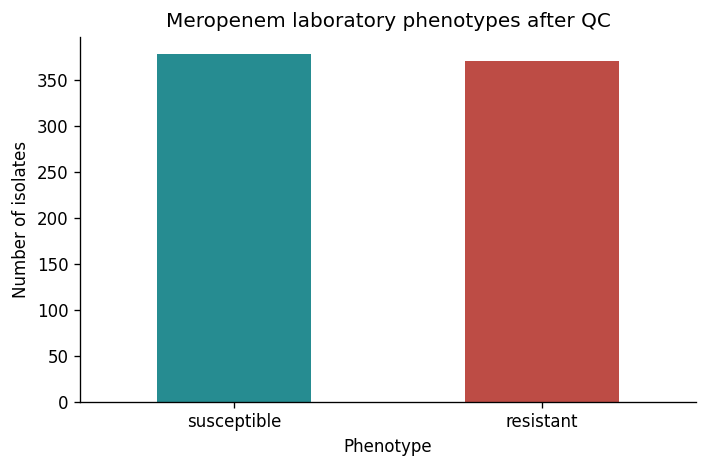

Resistant isolates account for 49.5% of this selected cohort. This is not a population prevalence estimate.

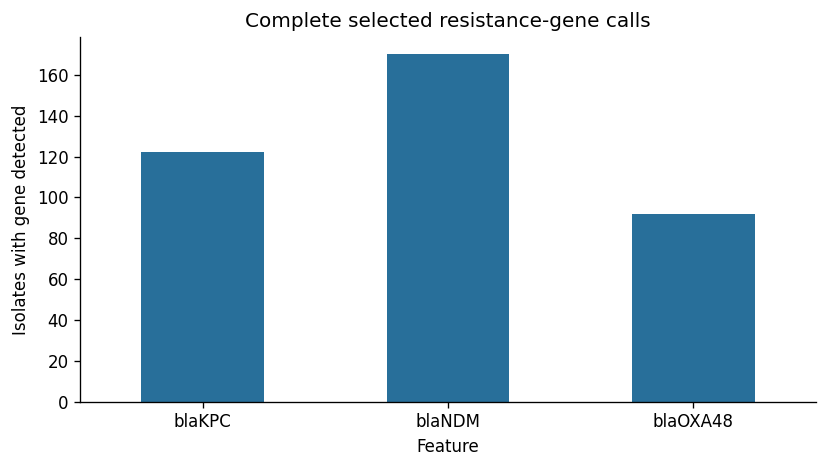

Gene-positive counts are blaKPC: 122, blaNDM: 170, blaOXA48: 92. Co-carriage means bars can overlap in membership.

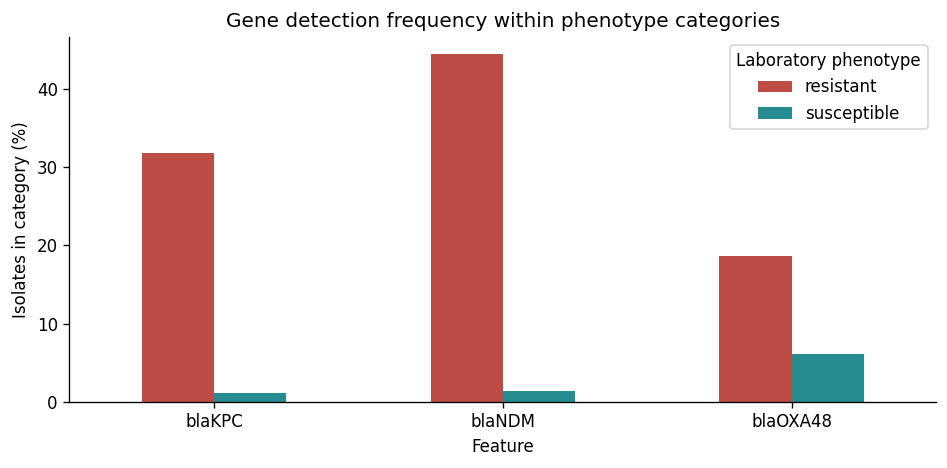

Each bar uses its own phenotype-category denominator. Differences describe association and do not demonstrate causation.

,combination,isolates,resistant,susceptible,resistant_fraction
0,000,407,61,346,0.149877
1,001,57,34,23,0.596491
2,010,128,123,5,0.960938
3,011,35,35,0,1.000000
4,100,115,111,4,0.965217
5,110,7,7,0,1.000000


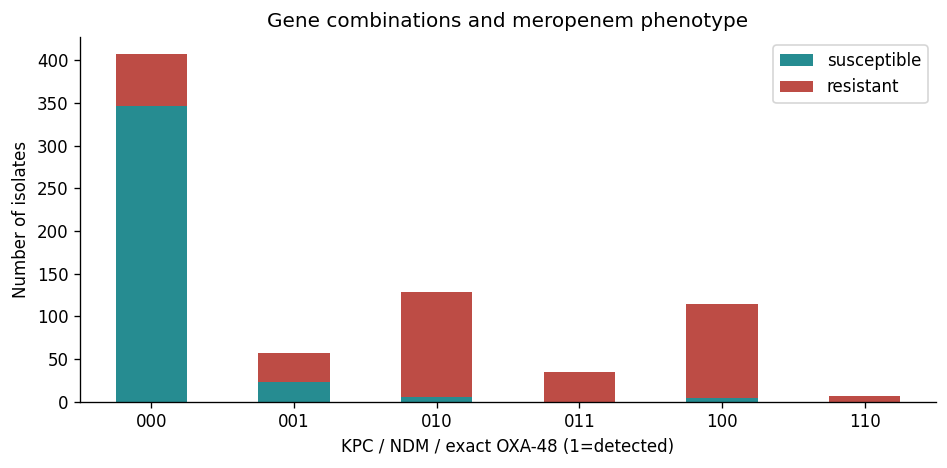

Among 407 isolates without a complete call for any selected feature, 61 (15.0%) are resistant. Three selected genes cannot explain all resistance.

In [5]:
counts=df.phenotype.value_counts().reindex(['susceptible','resistant'])
counts.plot.bar(color=['#268c91','#bd4c45'],rot=0,figsize=(6,4))
plt.title('Meropenem laboratory phenotypes after QC'); plt.xlabel('Phenotype'); plt.ylabel('Number of isolates')
save_plot('01_class_distribution')
say(f'Resistant isolates account for {df.y.mean():.1%} of this selected cohort. This is not a population prevalence estimate.')

df[FEATURES].sum().plot.bar(color='#286f9a',rot=0,figsize=(7,4))
plt.title('Complete selected resistance-gene calls'); plt.xlabel('Feature'); plt.ylabel('Isolates with gene detected')
save_plot('02_gene_frequency')
say('Gene-positive counts are '+', '.join(f'{f}: {df[f].sum()}' for f in FEATURES)+'. Co-carriage means bars can overlap in membership.')

rates=df.groupby('phenotype')[FEATURES].mean().T*100
rates.plot.bar(rot=0,figsize=(8,4),color=['#bd4c45','#268c91'])
plt.title('Gene detection frequency within phenotype categories'); plt.xlabel('Feature'); plt.ylabel('Isolates in category (%)')
plt.legend(title='Laboratory phenotype'); save_plot('03_gene_by_phenotype')
say('Each bar uses its own phenotype-category denominator. Differences describe association and do not demonstrate causation.')

df['combination']=df[FEATURES].astype(str).agg(''.join,axis=1)
comb=df.groupby('combination').agg(isolates=('y','size'),resistant=('y','sum')).reset_index()
comb['susceptible']=comb.isolates-comb.resistant; comb['resistant_fraction']=comb.resistant/comb.isolates
show_table(comb,'gene_combinations')
comb.set_index('combination')[['susceptible','resistant']].plot.bar(stacked=True,rot=0,figsize=(8,4),color=['#268c91','#bd4c45'])
plt.title('Gene combinations and meropenem phenotype'); plt.xlabel('KPC / NDM / exact OXA-48 (1=detected)'); plt.ylabel('Number of isolates')
save_plot('04_gene_combinations')
zero=df[df[FEATURES].sum(axis=1)==0]
say(f'Among {len(zero)} isolates without a complete call for any selected feature, '
    f'{int(zero.y.sum())} ({zero.y.mean():.1%}) are resistant. Three selected genes cannot explain all resistance.')

## 5. Core biological analysis
For each gene, compare resistance among carriers and non-carriers. Report two-sided Fisher exact tests,
sample odds ratios, conditional exact odds-ratio confidence intervals, and Benjamini–Hochberg adjusted p-values
across the three tests. An odds ratio greater than one indicates a positive association.
These are **exploratory marginal associations**: shared ancestry and source-study effects violate simple
independent-observation assumptions. The p-values and intervals are nominal, not population-adjusted causal evidence.
Gene-combination counts provide descriptive evidence; rare combinations should not support strong claims.

,gene,carrier_R,carrier_S,noncarrier_R,noncarrier_S,resistance_carriers,resistance_noncarriers,sample_OR,conditional_OR,CI_low,CI_high,p,BH_q
0,blaKPC,118,4,253,374,0.967213,0.403509,43.608696,43.450412,16.211306,164.167369,2.010052e-35,3.015077e-35
1,blaNDM,165,5,206,373,0.970588,0.355786,59.752427,59.486466,24.399638,188.641312,4.383979e-53,1.315194e-52
2,blaOXA48,69,23,302,355,0.750000,0.459665,3.526490,3.520822,2.108442,6.067488,1.797751e-07,1.797751e-07


**blaKPC:** 118/122 carriers resistant (96.7%), compared with 40.4% of non-carriers; sample OR 43.61, nominal BH q=3.02e-35.

**blaNDM:** 165/170 carriers resistant (97.1%), compared with 35.6% of non-carriers; sample OR 59.75, nominal BH q=1.32e-52.

**blaOXA48:** 69/92 carriers resistant (75.0%), compared with 46.0% of non-carriers; sample OR 3.53, nominal BH q=1.8e-07.

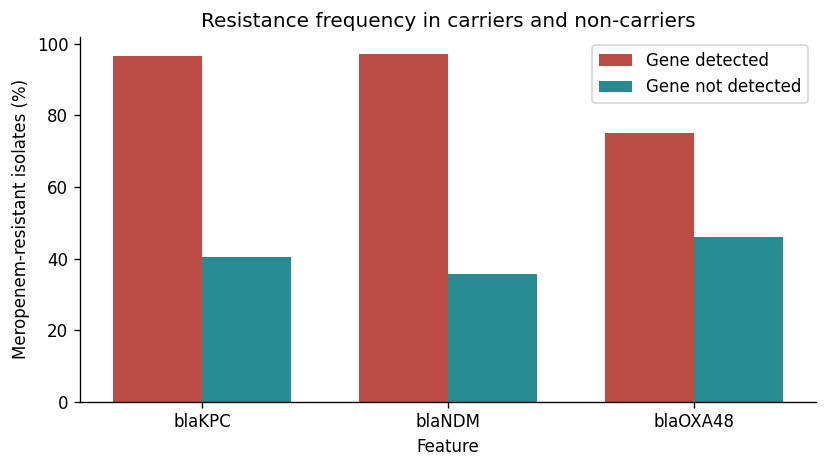

,biosample,assembly,project,calls
8,SAMN04014880,GCA_001874875.1,PRJNA292904,aac(3)-IId=COMPLETE;aac(6')-Ib-cr5=COMPLETE;aa...
9,SAMN04014881,GCA_001875105.1,PRJNA292904,aac(3)-IIe=COMPLETE;aac(6')-Ib-cr5=COMPLETE;aa...
11,SAMN04014887,GCA_003571745.1,PRJNA292904,aac(3)-IIe=COMPLETE;aac(6')-Ib-cr5=COMPLETE;aa...
12,SAMN04014888,GCA_002180075.1,PRJNA292904,aac(6')-Ib=COMPLETE;aadA2=COMPLETE;blaSHV-11=C...
14,SAMN04014907,GCA_002948565.1,PRJNA292904,aac(3)-IId=COMPLETE;aac(6')-Ib-cr5=COMPLETE;aa...
...,...,...,...,...
539,SAMN51434594,GCA_060293765.1,PRJNA1322038,aadA2=COMPLETE;blaCTX-M-15=COMPLETE;blaOXA-232...
551,SAMN51434606,GCA_060293525.1,PRJNA1322038,aac(6')-Ib-cr5=COMPLETE;aadA2=COMPLETE;blaCTX-...
588,SAMN51434646,GCA_060273435.1,PRJNA1322038,aac(6')-Iq=COMPLETE;aadA1=COMPLETE;aadA2=PARTI...
688,SAMN51434770,GCA_060271775.1,PRJNA1322038,aac(3)-IIe=COMPLETE;aac(6')-Ib-cr5=COMPLETE;ar...


In [6]:
assoc=[]
for gene in FEATURES:
    a=int(((df[gene]==1)&(df.y==1)).sum()); b=int(((df[gene]==1)&(df.y==0)).sum())
    c=int(((df[gene]==0)&(df.y==1)).sum()); d=int(((df[gene]==0)&(df.y==0)).sum())
    table=np.array([[a,b],[c,d]])
    test=fisher_exact(table); conditional=odds_ratio(table,kind='conditional'); ci=conditional.confidence_interval()
    assoc.append(dict(gene=gene,carrier_R=a,carrier_S=b,noncarrier_R=c,noncarrier_S=d,
        resistance_carriers=a/(a+b),resistance_noncarriers=c/(c+d),
        sample_OR=test.statistic,conditional_OR=conditional.statistic,CI_low=ci.low,CI_high=ci.high,p=test.pvalue))
association=pd.DataFrame(assoc)
order=np.argsort(association.p.to_numpy()); ranked=association.p.to_numpy()[order]
adjusted=np.minimum.accumulate((ranked*len(ranked)/np.arange(1,len(ranked)+1))[::-1])[::-1]
q=np.empty(len(ranked));q[order]=np.minimum(adjusted,1);association['BH_q']=q
show_table(association,'gene_associations')
for row in association.itertuples():
    say(f'**{row.gene}:** {row.carrier_R}/{row.carrier_R+row.carrier_S} carriers resistant '
        f'({row.resistance_carriers:.1%}), compared with {row.resistance_noncarriers:.1%} of non-carriers; '
        f'sample OR {row.sample_OR:.2f}, nominal BH q={row.BH_q:.3g}.')
fig,ax=plt.subplots(figsize=(7,4))
x=np.arange(3)
ax.bar(x-.18,association.resistance_carriers*100,.36,label='Gene detected',color='#bd4c45')
ax.bar(x+.18,association.resistance_noncarriers*100,.36,label='Gene not detected',color='#268c91')
ax.set(xticks=x,xticklabels=FEATURES,ylabel='Meropenem-resistant isolates (%)',xlabel='Feature',
       title='Resistance frequency in carriers and non-carriers');ax.legend();save_plot('05_carrier_resistance')
show_table(df[(df.y==1)&(df[FEATURES].sum(axis=1)==0)][['biosample','assembly','project','calls']], 'resistant_without_selected_genes')

## 6. Biological interpretation
Published evidence: NCBI explicitly cautions that detecting an AMR gene does not necessarily establish
phenotypic resistance. Expression, other mechanisms and breakpoints matter. Porin loss can change susceptibility
without adding one of the three selected genes. [NCBI interpretation guidance](https://github.com/ncbi/amr/wiki/Interpreting-results).

Vijayakumar and Ramaiah (2026) compared NCBI-derived K. pneumoniae genomes and reported carbapenemase
and porin differences associated with meropenem phenotypes. This supports considering mechanisms beyond
the three selected features, but is not independent validation: our public-data sources may overlap.
[Original study, DOI 10.3389/fmicb.2026.1851170](https://doi.org/10.3389/fmicb.2026.1851170).

The interpretation method required by the brief is comparison with scientific literature and curated
biological annotation guidance. No enrichment analysis is needed for three preselected resistance genes.
Exact OXA-48 is narrower than the OXA-48-like family. A gene-negative resistant isolate may carry a different
carbapenemase, porin alteration, an undetected gene or another mechanism. These are hypotheses unless the
relevant evidence is examined; this analysis does not establish a cause for each isolate.

Observed gene combinations: NDM plus exact OXA-48 (without KPC) occurred in 35 isolates, all resistant; KPC plus NDM (without exact OXA-48) occurred in seven, all resistant. These 100% observed proportions have finite, particularly small, denominators and do not imply perfect prediction in new isolates. Exact OXA-48 alone occurred in 57 isolates, of which 34 were resistant (59.6%).

In [7]:
top=association.sort_values('sample_OR',ascending=False).iloc[0]
say(f'**Our dataset:** {top.gene} has the largest marginal sample odds ratio ({top.sample_OR:.2f}). '
    f'{int(zero.y.sum())} resistant isolates have none of the three selected complete gene calls. '
    'The observed association supports predictive investigation, but gene carriage alone is not a susceptibility test. '
    'Study selection, co-carriage, incomplete assembly and unmeasured mechanisms can influence these findings.')

**Our dataset:** blaNDM has the largest marginal sample odds ratio (59.75). 61 resistant isolates have none of the three selected complete gene calls. The observed association supports predictive investigation, but gene carriage alone is not a susceptibility test. Study selection, co-carriage, incomplete assembly and unmeasured mechanisms can influence these findings.

## 7. Machine learning and model evaluation
The primary evaluation holds out the first fold of a seeded five-fold StratifiedGroupKFold split;
known PDS genomic clusters cannot cross the split. Unclustered isolates receive unique groups, which cannot
exclude unidentified relatedness or repeated patients. BioProjects may occur in both primary partitions.
We therefore add five separate study-held-out checks, purging any overlapping known clusters from training.
Holding every project and cluster together simultaneously creates a dominant connected group and is not
suitable for a balanced primary split in this dataset.

Models are specified in advance: majority-class DummyClassifier, L2 Logistic Regression (C=1), and
Random Forest (300 trees, depth ≤3, minimum leaf size 5). The binary features require no learned transformation;
an explicit identity preprocessing pipeline keeps predictor selection clear. Balanced class weights are used
for both learned models and calculated only during training. No oversampling or hyperparameter search is used.
Five-fold grouped CV is performed only on the training partition. The preferred model is chosen by mean
resistant-class CV F1, with recall used as the secondary criterion. Test results do not change that choice.

All classifiers use a fixed 0.5 probability threshold (the baseline predicts its training majority).
Accuracy, precision, recall, F1, balanced accuracy, ROC-AUC, PR-AUC and confusion matrices are reported.
MAE is omitted: on 0/1 predictions it equals the error rate and adds no distinct classification information.
Recall intervals use resampling of held-out clusters; they are exploratory, not clinical performance guarantees.

The saved `pr_auc` column uses average precision (scikit-learn average_precision_score), not trapezoidal PR area. Precision is set to zero when a model predicts no resistant isolates. For study subgroups with no resistant isolates, resistant recall/F1 and two-class metrics are undefined and left blank.

In [8]:
X=df[FEATURES]; y=df.y; groups=df.cluster
outer=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
train_idx,test_idx=next(outer.split(X,y,groups))
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
assert y.iloc[train_idx].nunique()==2 and y.iloc[test_idx].nunique()==2
Xtr,Xte=X.iloc[train_idx],X.iloc[test_idx];ytr,yte=y.iloc[train_idx],y.iloc[test_idx]
gtr=groups.iloc[train_idx]
models={
 'Majority baseline':DummyClassifier(strategy='most_frequent'),
 'Logistic Regression':LogisticRegression(C=1,solver='lbfgs',max_iter=1000,class_weight='balanced',random_state=SEED),
 'Random Forest':RandomForestClassifier(n_estimators=300,max_depth=3,min_samples_leaf=5,
     class_weight='balanced',random_state=SEED,n_jobs=1)}
def pipeline(model): return Pipeline([('binary_features',FunctionTransformer()),('model',clone(model))])
def metrics(ytrue,pred,prob):
    return dict(accuracy=accuracy_score(ytrue,pred),precision=precision_score(ytrue,pred,zero_division=0),
       recall=recall_score(ytrue,pred,zero_division=0) if np.sum(ytrue)>0 else np.nan,
       f1=f1_score(ytrue,pred,zero_division=0) if np.sum(ytrue)>0 else np.nan,
       balanced_accuracy=balanced_accuracy_score(ytrue,pred) if len(set(ytrue))==2 else np.nan,
       roc_auc=roc_auc_score(ytrue,prob) if len(set(ytrue))==2 else np.nan,
       pr_auc=average_precision_score(ytrue,prob) if len(set(ytrue))==2 else np.nan)
inner=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED+1)
folds=list(inner.split(Xtr,ytr,gtr));cv=[]
for name,model in models.items():
    for fold,(tr,va) in enumerate(folds,1):
        assert set(gtr.iloc[tr]).isdisjoint(set(gtr.iloc[va]))
        assert ytr.iloc[tr].nunique()==2 and ytr.iloc[va].nunique()==2
        fit=pipeline(model).fit(Xtr.iloc[tr],ytr.iloc[tr])
        cv.append(dict(model=name,fold=fold,**metrics(ytr.iloc[va],fit.predict(Xtr.iloc[va]),fit.predict_proba(Xtr.iloc[va])[:,1])))
cv=pd.DataFrame(cv);show_table(cv,'training_cv_folds')
cv_summary=cv.groupby('model')[['accuracy','precision','recall','f1']].agg(['mean','std'])
cv_summary.columns=['_'.join(c) for c in cv_summary.columns]
show_table(cv_summary.reset_index(),'training_cv_summary')
preferred=cv_summary.drop(index='Majority baseline').sort_values(['f1_mean','recall_mean'],ascending=False).index[0]
say(f'Chosen before test evaluation: **{preferred}**, using training-only CV F1 and recall.')
split=df[['biosample','project','cluster','cluster_known','y']].copy();split['partition']='train';split.loc[test_idx,'partition']='test'
show_table(split,'split_manifest')
show_table(split.groupby(['partition','y']).size().reset_index(name='isolates'),'split_counts')
print('Known cluster overlap: 0. Shared BioProjects:',len(set(df.iloc[train_idx].project)&set(df.iloc[test_idx].project)))

,model,fold,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc
0,Majority baseline,1,0.453125,0.453125,1.000000,0.623656,0.500000,0.500000,0.453125
1,Majority baseline,2,0.375000,0.000000,0.000000,0.000000,0.500000,0.500000,0.625000
2,Majority baseline,3,0.371212,0.000000,0.000000,0.000000,0.500000,0.500000,0.628788
3,Majority baseline,4,0.377358,0.377358,1.000000,0.547945,0.500000,0.500000,0.377358
4,Majority baseline,5,0.420561,0.420561,1.000000,0.592105,0.500000,0.500000,0.420561
5,Logistic Regression,1,0.914062,0.927273,0.879310,0.902655,0.911084,0.924877,0.905341
6,Logistic Regression,2,0.890625,0.945946,0.875000,0.909091,0.895833,0.929688,0.949747
7,Logistic Regression,3,0.886364,0.947368,0.867470,0.905660,0.892919,0.913573,0.931918
8,Logistic Regression,4,0.792453,0.800000,0.600000,0.685714,0.754545,0.777273,0.730943
9,Logistic Regression,5,0.887850,0.866667,0.866667,0.866667,0.884946,0.891935,0.828913


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Logistic Regression,0.874271,0.047105,0.897451,0.063595,0.817689,0.121806,0.853957,0.095592
1,Majority baseline,0.399451,0.036090,0.250209,0.229984,0.600000,0.547723,0.352741,0.323128
2,Random Forest,0.874271,0.047105,0.897451,0.063595,0.817689,0.121806,0.853957,0.095592


Chosen before test evaluation: **Logistic Regression**, using training-only CV F1 and recall.

,biosample,project,cluster,cluster_known,y,partition
0,SAMN03455989,PRJNA279669,SAMN03455989,False,0,train
1,SAMN03455990,PRJNA430813,PDS000006932,True,1,train
2,SAMN03455995,PRJNA279675,SAMN03455995,False,1,test
3,SAMN03892120,PRJNA278886,PDS000011646,True,0,train
4,SAMN04014844,PRJNA292901,PDS000076329,True,1,train
...,...,...,...,...,...,...
744,SAMN55933027,PRJNA1427745,PDS000267523,True,1,train
745,SAMN55933030,PRJNA1427745,SAMN55933030,False,0,train
746,SAMN55933031,PRJNA1427745,SAMN55933031,False,0,train
747,SAMN55933036,PRJNA1427745,PDS000250773,True,0,train


,partition,y,isolates
0,test,0,83
1,test,1,65
2,train,0,295
3,train,1,306


Known cluster overlap: 0. Shared BioProjects: 19


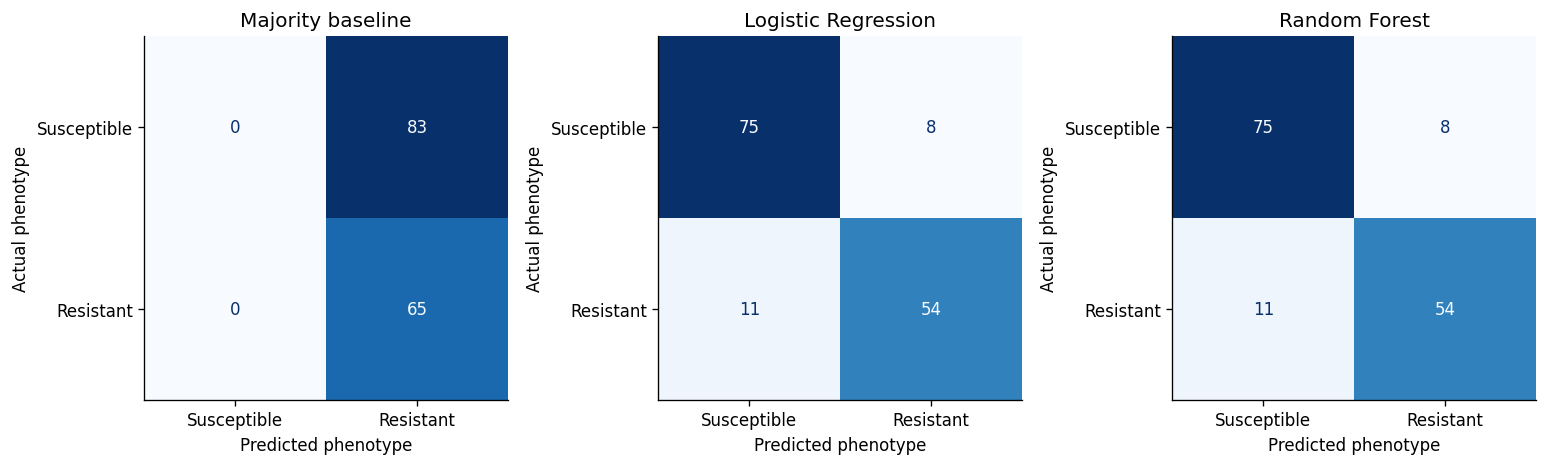

,model,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc
0,Majority baseline,0.439189,0.439189,1.000000,0.610329,0.500000,0.500000,0.439189
1,Logistic Regression,0.871622,0.870968,0.830769,0.850394,0.867192,0.894347,0.872901
2,Random Forest,0.871622,0.870968,0.830769,0.850394,0.867192,0.894347,0.872901


,biosample,project,cluster,standard,y,Majority baseline_prediction,Majority baseline_probability,Logistic Regression_prediction,Logistic Regression_probability,Random Forest_prediction,Random Forest_probability
2,SAMN03455995,PRJNA279675,SAMN03455995,CLSI,1,1,1.0,1,0.928886,1,0.970098
13,SAMN04014890,PRJNA292904,PDS000005578,CLSI,1,1,1.0,1,0.926246,1,0.964927
16,SAMN04014916,PRJNA292904,PDS000006573,CLSI,1,1,1.0,0,0.180583,0,0.149429
19,SAMN04014928,PRJNA292904,PDS000005981,CLSI,0,1,1.0,0,0.180583,0,0.149429
29,SAMN04014967,PRJNA292902,PDS000006905,CLSI,1,1,1.0,1,0.928886,1,0.970098
...,...,...,...,...,...,...,...,...,...,...,...
724,SAMN51434893,PRJNA1322038,SAMN51434893,EUCAST,0,1,1.0,0,0.180583,0,0.149429
728,SAMN51434900,PRJNA1322038,PDS000104479,EUCAST,1,1,1.0,0,0.180583,0,0.149429
731,SAMN55283965,PRJNA1420937,PDS000105720,CLSI,0,1,1.0,0,0.180583,0,0.149429
733,SAMN55283967,PRJNA1420937,SAMN55283967,CLSI,0,1,1.0,0,0.180583,0,0.149429


,model,recall_low,recall_high
0,Majority baseline,1.000000,1.000000
1,Logistic Regression,0.676912,0.938782
2,Random Forest,0.676912,0.938782


**Majority baseline:** held-out F1 0.610, resistant recall 1.000, accuracy 0.439; 0 resistant isolates predicted susceptible.

**Logistic Regression:** held-out F1 0.850, resistant recall 0.831, accuracy 0.872; 11 resistant isolates predicted susceptible.

**Random Forest:** held-out F1 0.850, resistant recall 0.831, accuracy 0.872; 11 resistant isolates predicted susceptible.

In [9]:
test_results=[];predictions=df.iloc[test_idx][['biosample','project','cluster','standard','y']].copy();fitted={}
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(name,model) in zip(axes,models.items()):
    fit=pipeline(model).fit(Xtr,ytr);fitted[name]=fit
    pred=fit.predict(Xte);prob=fit.predict_proba(Xte)[:,1]
    test_results.append(dict(model=name,**metrics(yte,pred,prob)))
    predictions[name+'_prediction']=pred;predictions[name+'_probability']=prob
    ConfusionMatrixDisplay.from_predictions(yte,pred,labels=[0,1],display_labels=['Susceptible','Resistant'],ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(name);ax.set_xlabel('Predicted phenotype');ax.set_ylabel('Actual phenotype')
save_plot('06_confusion_matrices')
test_results=pd.DataFrame(test_results);show_table(test_results,'test_metrics');show_table(predictions,'test_predictions')
unique_groups=predictions.cluster.unique();recall_ci=[]
for name in models:
    rng=np.random.default_rng(SEED)  # Paired resamples across models.
    recalls=[]
    blocks=[predictions[predictions.cluster==g] for g in unique_groups]
    positives=np.array([b.y.sum() for b in blocks])
    truepositives=np.array([((b.y==1)&(b[name+'_prediction']==1)).sum() for b in blocks])
    for _ in range(1000):
        chosen=rng.integers(0,len(blocks),len(blocks))
        if positives[chosen].sum()>0: recalls.append(truepositives[chosen].sum()/positives[chosen].sum())
    low,high=np.quantile(recalls,[.025,.975]);recall_ci.append(dict(model=name,recall_low=low,recall_high=high))
show_table(pd.DataFrame(recall_ci),'recall_cluster_bootstrap')
for r in test_results.itertuples():
    fn=int(((predictions.y==1)&(predictions[r.model+'_prediction']==0)).sum())
    say(f'**{r.model}:** held-out F1 {r.f1:.3f}, resistant recall {r.recall:.3f}, '
        f'accuracy {r.accuracy:.3f}; {fn} resistant isolates predicted susceptible.')

### Sensitivity checks and model interpretation
The five largest eligible BioProjects are selected by sample count, not model performance. Each is held out
in turn; known test clusters are removed from its training data. These are additional study-shift assessments,
not independent external validation and not a basis for retuning the primary models. Studies with only one
class are reported but AUC is undefined. Small denominators warrant caution.

In [10]:
study_results=[]
for project in df.project.value_counts().head(5).index:
    mask=df.project==project
    held_clusters=set(df.loc[mask & df.cluster_known,'cluster'])
    train_mask=(~mask)&(~df.cluster.isin(held_clusters))
    assert not set(df.loc[train_mask,'cluster']) & set(df.loc[mask,'cluster'])
    if df.loc[train_mask,'y'].nunique()<2: continue
    for name,model in models.items():
        fit=pipeline(model).fit(X.loc[train_mask],y.loc[train_mask])
        study_results.append(dict(project=project,model=name,n_train=int(train_mask.sum()),
          n_test=int(mask.sum()),resistant_test=int(y[mask].sum()),
          purged=int((~mask).sum()-train_mask.sum()),**metrics(y[mask],fit.predict(X[mask]),fit.predict_proba(X[mask])[:,1])))
study_results=pd.DataFrame(study_results);show_table(study_results,'study_held_out_metrics')
subgroups=[]
for standard,part in predictions.groupby('standard'):
    for name in models:
        subgroups.append(dict(standard=standard,model=name,n=len(part),resistant=int(part.y.sum()),
          **metrics(part.y,part[name+'_prediction'],part[name+'_probability'])))
show_table(pd.DataFrame(subgroups),'test_standard_subgroups')
patterns=pd.DataFrame([[int(v) for v in format(i,'03b')] for i in range(8)],columns=FEATURES)
for name,fit in fitted.items():patterns[name+'_P_resistant']=fit.predict_proba(patterns[FEATURES])[:,1]
show_table(patterns,'model_gene_patterns')
lr=fitted['Logistic Regression'].named_steps['model']
show_table(pd.DataFrame({'gene':FEATURES,'coefficient':lr.coef_[0],
 'model_odds_multiplier':np.exp(lr.coef_[0]),
 'forest_impurity_importance':fitted['Random Forest'].named_steps['model'].feature_importances_}), 'model_feature_interpretation')
say('Logistic coefficients describe the fitted regularized, class-weighted model, not causal effect sizes. '
    'Forest importance can be distorted by correlated predictors. Pattern probabilities are uncalibrated research scores. '
    'Study-held-out results and standard subgroups show how performance changes across data sources.')

,project,model,n_train,n_test,resistant_test,purged,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc
0,PRJNA1322038,Majority baseline,516,220,152,13,0.309091,0.000000,0.000000,0.000000,0.500000,0.500000,0.690909
1,PRJNA1322038,Logistic Regression,516,220,152,13,0.945455,1.000000,0.921053,0.958904,0.960526,0.960526,0.975598
2,PRJNA1322038,Random Forest,516,220,152,13,0.945455,1.000000,0.921053,0.958904,0.960526,0.960526,0.975598
3,PRJNA278886,Majority baseline,594,147,22,8,0.149660,0.149660,1.000000,0.260355,0.500000,0.500000,0.149660
4,PRJNA278886,Logistic Regression,594,147,22,8,0.904762,1.000000,0.363636,0.533333,0.681818,0.681818,0.458874
5,PRJNA278886,Random Forest,594,147,22,8,0.904762,1.000000,0.363636,0.533333,0.681818,0.681818,0.458874
6,PRJNA1160997,Majority baseline,660,82,57,7,0.304878,0.000000,0.000000,0.000000,0.500000,0.500000,0.695122
7,PRJNA1160997,Logistic Regression,660,82,57,7,0.780488,0.774648,0.964912,0.859375,0.662456,0.822456,0.885845
8,PRJNA1160997,Random Forest,660,82,57,7,0.780488,0.774648,0.964912,0.859375,0.662456,0.822456,0.885845
9,PRJNA1271593,Majority baseline,697,45,0,7,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN


,standard,model,n,resistant,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc
0,CLSI,Majority baseline,77,23,0.298701,0.298701,1.000000,0.460000,0.500000,0.500000,0.298701
1,CLSI,Logistic Regression,77,23,0.883117,0.937500,0.652174,0.769231,0.816828,0.821659,0.747918
2,CLSI,Random Forest,77,23,0.883117,0.937500,0.652174,0.769231,0.816828,0.821659,0.747918
3,EUCAST,Majority baseline,71,42,0.591549,0.591549,1.000000,0.743363,0.500000,0.500000,0.591549
4,EUCAST,Logistic Regression,71,42,0.859155,0.847826,0.928571,0.886364,0.843596,0.919540,0.927492
5,EUCAST,Random Forest,71,42,0.859155,0.847826,0.928571,0.886364,0.843596,0.919540,0.927492


,blaKPC,blaNDM,blaOXA48,Majority baseline_P_resistant,Logistic Regression_P_resistant,Random Forest_P_resistant
0,0,0,0,1.0,0.180583,0.149429
1,0,0,1,1.0,0.570033,0.600264
2,0,1,0,1.0,0.926246,0.964927
3,0,1,1,1.0,0.986937,0.994897
4,1,0,0,1.0,0.928886,0.970098
5,1,0,1,1.0,0.987434,0.784100
6,1,1,0,1.0,0.998658,0.972003
7,1,1,1,1.0,0.999777,0.986154


,gene,coefficient,model_odds_multiplier,forest_impurity_importance
0,blaKPC,4.082095,59.269512,0.435773
1,blaNDM,4.042801,56.985738,0.499552
2,blaOXA48,1.794387,6.015787,0.064676


Logistic coefficients describe the fitted regularized, class-weighted model, not causal effect sizes. Forest importance can be distorted by correlated predictors. Pattern probabilities are uncalibrated research scores. Study-held-out results and standard subgroups show how performance changes across data sources.

## 8. Conclusions, limitations and future recommendations
The generated conclusions below use actual outputs. Negative and inconclusive results are retained.
Limitations include selected public submissions, missing breakpoint years, mixed CLSI/EUCAST criteria,
mixed reference database versions and annotation modes, uncertain assembly completeness, exclusion of ambiguous
calls, unmeasured lineage and patient structure, and omission of other carbapenemases and regulatory mechanisms.
Unknown cluster membership is not proof of independence. The dataset may overlap published studies.
Fisher evidence is exploratory and not population-structure-adjusted. Only eight predictor patterns are possible;
model complexity cannot recover information that the three features omit.

Future work: inspect underlying sequences and coverage; use a version-frozen annotation pipeline; collect
consistent laboratory breakpoint metadata; assess additional carbapenemases/porins with approval; perform
lineage-aware and geographic external validation; evaluate calibration and thresholds using training data;
and involve microbiology expertise before considering any clinical application.

In [11]:
best=test_results.set_index('model').loc[preferred]
baseline=test_results.set_index('model').loc['Majority baseline']
ranking=test_results[test_results.model!='Majority baseline'].sort_values('f1',ascending=False)
observed=' and '.join(ranking.loc[np.isclose(ranking.f1,ranking.f1.max()),'model'])
summary={
 'initial_isolates':len(genomes),'candidate_isolates':807,'final_isolates':len(df),
 'resistant':int(df.y.sum()),'susceptible':int((1-df.y).sum()),
 'train':len(train_idx),'test':len(test_idx),'preferred_cv_model':preferred,
 'highest_observed_test_f1_model':observed,'preferred_test_metrics':best.to_dict(),
 'baseline_test_metrics':baseline.to_dict(),'gene_negative_resistant':int(zero.y.sum()),
 'gene_negative_total':len(zero),'largest_marginal_OR_gene':top.gene,
 'known_cluster_overlap':0,'missing_cluster_final':int((~df.cluster_known).sum())}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))
conclusions=f"""# Results and conclusions

1. **Data acquisition:** obtained 1,169 BioSample-matched isolates from NCBI, with laboratory meropenem phenotypes and AMRFinderPlus annotations. The approved assembly/standard candidate cohort contained 807 isolates.
2. **Cleaning and exploration:** retained {len(df)} isolates after all specified checks: {int(df.y.sum())} resistant and {int((1-df.y).sum())} susceptible. All three binary predictors are complete in the final table; unresolved calls were excluded, not imputed.
3. **Biological associations:** {top.gene} had the largest marginal sample odds ratio ({top.sample_OR:.2f}). There were {int(zero.y.sum())} resistant isolates among {len(zero)} without the selected complete gene calls. Associations are exploratory and do not prove causation or explain all resistance.
4. **Prediction:** training-only grouped CV selected {preferred}. On {len(test_idx)} held-out isolates it achieved accuracy {best.accuracy:.3f}, precision {best.precision:.3f}, resistant recall {best.recall:.3f}, and F1 {best.f1:.3f}. Baseline F1 was {baseline.f1:.3f}. The highest observed learned-model test F1 was from {observed}; test ranking does not revise the CV choice or establish statistical superiority.

**Research question:** the selected features provide {'better' if best.f1>baseline.f1 else 'no demonstrated better'} held-out F1 than the simple baseline in this selected cohort. They provide incomplete information and are insufficient for reliable clinical susceptibility prediction on their own. The study-held-out results should be read alongside this primary result.

**Limits and next steps:** preserve the limitations in notebook stage 8, verify sequence quality and uncertain calls, standardize phenotype/annotation provenance, and seek independent lineage/geographic validation. This is research only.
"""
(RESULTS/'conclusions.md').write_text(conclusions,encoding='utf-8');say(conclusions)
# Explicit validation checks of computed outputs and partitions.
assert len(predictions)==len(test_idx)
assert set(split[split.partition=='train'].biosample).isdisjoint(split[split.partition=='test'].biosample)
assert set(split[split.partition=='train'].cluster).isdisjoint(split[split.partition=='test'].cluster)
assert set(X.columns)==set(FEATURES)
for name in models:
    assert confusion_matrix(predictions.y,predictions[name+'_prediction'],labels=[0,1]).sum()==len(predictions)
print('Validation passed: matched identities, binary features, unique assemblies, disjoint partitions/groups, complete prediction counts.')

# Results and conclusions

1. **Data acquisition:** obtained 1,169 BioSample-matched isolates from NCBI, with laboratory meropenem phenotypes and AMRFinderPlus annotations. The approved assembly/standard candidate cohort contained 807 isolates.
2. **Cleaning and exploration:** retained 749 isolates after all specified checks: 371 resistant and 378 susceptible. All three binary predictors are complete in the final table; unresolved calls were excluded, not imputed.
3. **Biological associations:** blaNDM had the largest marginal sample odds ratio (59.75). There were 61 resistant isolates among 407 without the selected complete gene calls. Associations are exploratory and do not prove causation or explain all resistance.
4. **Prediction:** training-only grouped CV selected Logistic Regression. On 148 held-out isolates it achieved accuracy 0.872, precision 0.871, resistant recall 0.831, and F1 0.850. Baseline F1 was 0.610. The highest observed learned-model test F1 was from Logistic Regression and Random Forest; test ranking does not revise the CV choice or establish statistical superiority.

**Research question:** the selected features provide better held-out F1 than the simple baseline in this selected cohort. They provide incomplete information and are insufficient for reliable clinical susceptibility prediction on their own. The study-held-out results should be read alongside this primary result.

**Limits and next steps:** preserve the limitations in notebook stage 8, verify sequence quality and uncertain calls, standardize phenotype/annotation provenance, and seek independent lineage/geographic validation. This is research only.


Validation passed: matched identities, binary features, unique assemblies, disjoint partitions/groups, complete prediction counts.


### References
- NCBI. AST Browser documentation: https://www.ncbi.nlm.nih.gov/pathogens/docs/ast/
- NCBI. AMRFinderPlus interpretation: https://github.com/ncbi/amr/wiki/Interpreting-results
- NCBI. Molecular-data usage policy: https://www.ncbi.nlm.nih.gov/home/about/policies/
- Vijayakumar S, Ramaiah S (2026). A comparative genomic approach to identify determinants of meropenem resistance in Klebsiella pneumoniae using pan-genome-wide association analysis. https://doi.org/10.3389/fmicb.2026.1851170
- scikit-learn. StratifiedGroupKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
